# CV-EDA — Phân tích khám phá dữ liệu hình ảnh SHEL5K (Tuần 3)

**Mục đích:** hiểu đặc điểm dữ liệu trước khi tiền xử lý và huấn luyện, gắn mỗi phát hiện với mục tiêu bài toán
(mAP@0.5 ≥ 0,85; Recall `person_no_helmet` ≥ 0,80; khái quát sang camera công trường thực tế).

**Nội dung theo đề cương (Bước 3):** phân bố lớp, kích thước ảnh, tỉ lệ diện tích hộp, số đối tượng trên ảnh, độ mờ
(phương sai toán tử Laplace); phát hiện ảnh lỗi, ảnh trùng lặp, nhãn có tọa độ bất hợp lý, mất cân bằng lớp.

**Điều chỉnh so với đề cương:**
- Phần cần giải mã ảnh chạy trên **toàn bộ 5.000 ảnh** thay vì mẫu 500 ảnh. Ảnh chỉ khoảng 416×416 và được đọc lần lượt
  từng ảnh nên vừa với RAM 8 GB; tìm ảnh trùng trên mẫu 500 ảnh sẽ bỏ sót gần hết các cặp trùng.
- Bổ sung **độ sáng** (phục vụ phân tích lỗi theo điều kiện chiếu sáng ở Mục tiêu 3) và **phân tích vùng phản chiếu**
  (phát hiện chính của kiểm định nhãn Tuần 2).

**Đầu vào:** `data/SHEL5K/Images/*.png`, bảng đối tượng `reports/integrity/objects.csv` (Tuần 1), kết quả kiểm định
`reports/audit/label_audit_results.csv` (Tuần 2). **Đầu ra:** biểu đồ trong `reports/eda/`, bảng chỉ số ảnh
`reports/eda/image_stats.csv`, nhóm ảnh trùng `reports/eda/duplicate_groups.csv`.

In [1]:
import hashlib, time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
IMG_DIR = ROOT / "data/SHEL5K/Images"
OUT = ROOT / "reports/eda"
OUT.mkdir(parents=True, exist_ok=True)

CLASSES = ["helmet", "head", "head_with_helmet", "person_with_helmet", "person_no_helmet", "face"]
PRIORITY = "person_no_helmet"

# Bảng màu (dataviz, chế độ sáng): một màu chính, màu cam chỉ để làm nổi lớp ưu tiên
BLUE, ORANGE, INK, INK2, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "font.family": "Arial", "font.size": 10, "axes.edgecolor": INK2, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})

def save(fig, name):
    fig.savefig(OUT / name)
    plt.show()

## 1. Dữ liệu nhãn

Dùng bảng đối tượng đã trích từ XML ở Tuần 1. 8 hộp lớp lạ `person` được ánh xạ sang `person_with_helmet`, giống bước
chuyển đổi nhãn ở Tuần 2.

In [2]:
obj = pd.read_csv(ROOT / "reports/integrity/objects.csv")
obj["class"] = obj["class"].replace({"person": "person_with_helmet"})
obj["bw"] = obj.xmax - obj.xmin
obj["bh"] = obj.ymax - obj.ymin
obj["area_ratio"] = obj.bw * obj.bh / (obj.width * obj.height)
obj["short_side"] = obj[["bw", "bh"]].min(axis=1)
print(f"{obj.filename.nunique()} ảnh, {len(obj)} hộp, lớp: {sorted(obj['class'].unique())}")

5000 ảnh, 75578 hộp, lớp: ['face', 'head', 'head_with_helmet', 'helmet', 'person_no_helmet', 'person_with_helmet']


## 2. Phân bố lớp và mất cân bằng lớp

                    số hộp  tỉ lệ %
class                              
helmet               19252     25.5
head_with_helmet     16048     21.2
person_with_helmet   14775     19.5
face                 14135     18.7
head                  6120      8.1
person_no_helmet      5248      6.9
Tỉ lệ mất cân bằng (lớp nhiều nhất / person_no_helmet): 3.67


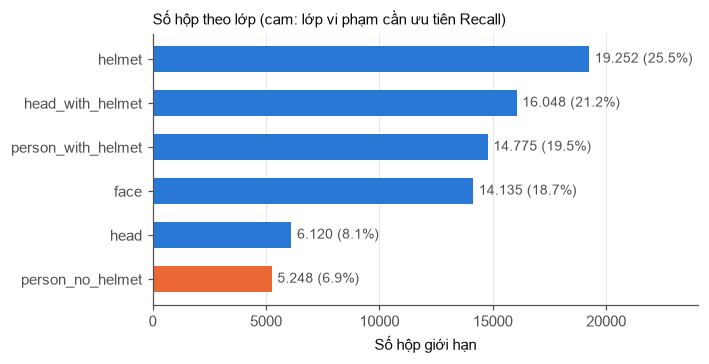

In [3]:
counts = obj["class"].value_counts().reindex(CLASSES).sort_values()
share = counts / counts.sum() * 100
print(pd.DataFrame({"số hộp": counts, "tỉ lệ %": share.round(1)}).sort_values("số hộp", ascending=False))
print(f"Tỉ lệ mất cân bằng (lớp nhiều nhất / {PRIORITY}): {counts.max() / counts[PRIORITY]:.2f}")

fig, ax = plt.subplots(figsize=(6.4, 3.2))
colors = [ORANGE if c == PRIORITY else BLUE for c in counts.index]
ax.barh(counts.index, counts.values, color=colors, height=0.6)
for y, (n, p) in enumerate(zip(counts.values, share.values)):
    ax.text(n + 250, y, f"{n:,} ({p:.1f}%)".replace(",", "."), va="center", color=INK2, fontsize=9)
ax.set_xlabel("Số hộp giới hạn")
ax.set_xlim(0, counts.max() * 1.25)
ax.grid(axis="y", visible=False)
ax.set_title("Số hộp theo lớp (cam: lớp vi phạm cần ưu tiên Recall)", loc="left", fontsize=10)
save(fig, "fig_class_distribution.png")

**Diễn giải.** Lớp vi phạm `person_no_helmet` có ít hộp nhất (6,9%), ít hơn lớp nhiều nhất (`helmet`) 3,67 lần; `head`
(đầu không đội mũ, dấu hiệu vi phạm ở mức đầu) cũng chỉ chiếm 8,1%. Mô hình sẽ thấy ít ví dụ vi phạm hơn hẳn ví dụ tuân
thủ, nên Recall của lớp ưu tiên có nguy cơ thấp hơn các lớp khác. Đây là căn cứ cho cấu hình M2 (xử lý mất cân bằng lớp)
và cho việc chia tập có phân tầng theo lớp ở Tuần 4.

## 3. Kích thước ảnh

In [4]:
sizes = obj.drop_duplicates("filename").groupby(["width", "height"]).size().rename("số ảnh")
print(sizes)
print(f"Hệ số phóng to khi huấn luyện ở 640 px: {640 / 416:.2f}")

width  height
415    415         23
       416        324
416    415       2461
       416       2192
Name: số ảnh, dtype: int64
Hệ số phóng to khi huấn luyện ở 640 px: 1.54


**Diễn giải.** Gần như toàn bộ ảnh có cùng kích thước 415–416 pixel (chênh 1 pixel do làm tròn khi thu nhỏ), nên không cần
bước chuẩn hóa kích thước riêng. Khi huấn luyện ở 640 pixel như đề cương, ảnh bị phóng to 1,54 lần: không thêm chi tiết
mới, nhưng làm vật thể nhỏ chiếm nhiều ô hơn trên lưới đặc trưng P3.

## 4. Kích thước hộp giới hạn

Nhóm kích thước theo quy ước COCO, tính trên diện tích hộp ở ảnh gốc: **nhỏ** < 32², **trung bình** 32²–96², **lớn** > 96²
pixel. Cách chia này được dùng lại cho phân tích lỗi theo kích thước ở Tuần 8.

size_group            nhỏ  trung bình    lớn  cạnh ngắn trung vị (px)  \
class                                                                   
helmet              69.95       28.99   1.06                     19.0   
head                74.69       24.98   0.33                     20.0   
head_with_helmet    56.13       40.91   2.96                     26.0   
person_with_helmet   9.62       45.28  45.10                     57.0   
person_no_helmet    11.20       54.21  34.58                     47.0   
face                90.94        8.98   0.07                     13.0   

size_group          diện tích trung vị (% ảnh)  
class                                           
helmet                                    0.27  
head                                      0.29  
head_with_helmet                          0.48  
person_with_helmet                        4.53  
person_no_helmet                          3.44  
face                                      0.13  

Toàn bộ: {'nhỏ': 55.5,

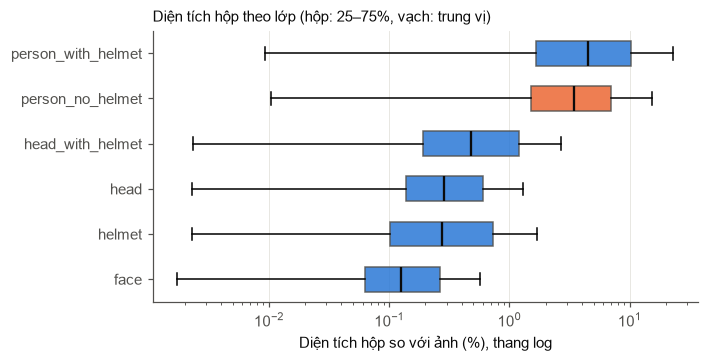

In [5]:
obj["size_group"] = pd.cut(obj.bw * obj.bh, [0, 32**2, 96**2, np.inf], labels=["nhỏ", "trung bình", "lớn"], right=False)
size_tab = pd.crosstab(obj["class"], obj["size_group"], normalize="index").reindex(CLASSES) * 100
size_tab["cạnh ngắn trung vị (px)"] = obj.groupby("class").short_side.median()
size_tab["diện tích trung vị (% ảnh)"] = obj.groupby("class").area_ratio.median() * 100
print(size_tab.round(2))
print("\nToàn bộ:", (obj.size_group.value_counts(normalize=True) * 100).round(1).to_dict())

order = obj.groupby("class").area_ratio.median().sort_values().index
fig, ax = plt.subplots(figsize=(6.4, 3.2))
data = [obj.loc[obj["class"] == c, "area_ratio"] * 100 for c in order]
bp = ax.boxplot(data, orientation="horizontal", tick_labels=order, showfliers=False, widths=0.55, patch_artist=True,
                medianprops={"color": INK, "linewidth": 1.5})
for patch, c in zip(bp["boxes"], order):
    patch.set(facecolor=ORANGE if c == PRIORITY else BLUE, alpha=0.85, edgecolor=INK2)
ax.set_xscale("log")
ax.set_xlabel("Diện tích hộp so với ảnh (%), thang log")
ax.grid(axis="y", visible=False)
ax.set_title("Diện tích hộp theo lớp (hộp: 25–75%, vạch: trung vị)", loc="left", fontsize=10)
save(fig, "fig_box_area_by_class.png")

**Diễn giải.** 55,5% số hộp thuộc nhóm nhỏ (< 32×32 pixel). `face` (91% nhỏ), `head` (75%) và `helmet` (70%) chủ yếu là vật
thể nhỏ, còn hai lớp người chủ yếu ở nhóm trung bình và lớn. Với lớp vi phạm `person_no_helmet` (chỉ 11% nhỏ), khó khăn
chính là **số lượng ít** chứ không phải kích thước; còn `head` vừa ít vừa nhỏ. Điều này củng cố việc đánh giá cơ chế
STAL hướng tới vật thể nhỏ của YOLO26 (M1) và việc phân tích lỗi theo nhóm kích thước ở Tuần 8.

### Hộp quá nhỏ và tọa độ bất hợp lý

In [6]:
import json
integ = json.loads((ROOT / "reports/integrity/summary.json").read_text())
print("Kiểm tra tọa độ (Tuần 1): tọa độ không hợp lệ =", len(integ["invalid_boxes"]), "| kích thước XML khác ảnh thật =", len(integ["size_mismatches"]))
tiny = pd.DataFrame({
    "cạnh ngắn < 4 px": obj[obj.short_side < 4].groupby("class").size(),
    "cạnh ngắn < 8 px": obj[obj.short_side < 8].groupby("class").size(),
}).reindex(CLASSES).fillna(0).astype(int)
tiny.loc["Tổng"] = tiny.sum()
print(tiny)
print(f"Tỉ lệ hộp có cạnh ngắn < 8 px: {(obj.short_side < 8).mean() * 100:.2f}%")

Kiểm tra tọa độ (Tuần 1): tọa độ không hợp lệ = 0 | kích thước XML khác ảnh thật = 0
                    cạnh ngắn < 4 px  cạnh ngắn < 8 px
class                                                 
helmet                           219              1943
head                              35               355
head_with_helmet                  59               653
person_with_helmet                 0                90
person_no_helmet                   1                73
face                             103              2390
Tổng                             417              5504
Tỉ lệ hộp có cạnh ngắn < 8 px: 7.28%


**Diễn giải.** Không có tọa độ bất hợp lý (đã kiểm tra toàn bộ ở Tuần 1). Tuy nhiên 7,3% số hộp có cạnh ngắn dưới 8 pixel,
tức dưới ngưỡng "nhìn thấy rõ" dùng khi kiểm định nhãn, chủ yếu là `face` và `helmet`; 417 hộp nhỏ hơn 4 pixel gần như
không thể học được. Đây là ứng viên cân nhắc lọc ở Tuần 4, cần so sánh định lượng trước – sau chứ không lọc tùy tiện.

## 5. Số đối tượng trên mỗi ảnh

count    5000.00
mean       15.12
std        12.38
min         1.00
25%         6.00
50%        11.00
75%        20.00
max       170.00
dtype: float64
Số ảnh có > 50 đối tượng: 96


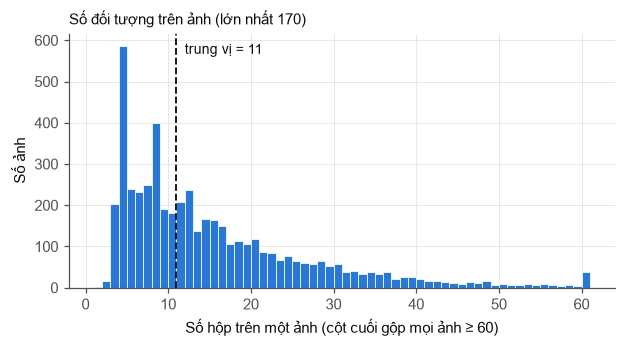

In [7]:
per_img = obj.groupby("filename").size()
print(per_img.describe().round(2))
print("Số ảnh có > 50 đối tượng:", (per_img > 50).sum())

fig, ax = plt.subplots(figsize=(6.4, 3.0))
ax.hist(per_img.clip(upper=60), bins=np.arange(1, 62), color=BLUE, edgecolor="white", linewidth=0.5)
ax.axvline(per_img.median(), color=INK, linewidth=1.2, linestyle="--")
ax.text(per_img.median() + 1, ax.get_ylim()[1] * 0.92, f"trung vị = {per_img.median():.0f}", color=INK, fontsize=9)
ax.set_xlabel("Số hộp trên một ảnh (cột cuối gộp mọi ảnh ≥ 60)")
ax.set_ylabel("Số ảnh")
ax.set_title(f"Số đối tượng trên ảnh (lớn nhất {per_img.max()})", loc="left", fontsize=10)
save(fig, "fig_objects_per_image.png")

**Diễn giải.** Trung vị 11 hộp/ảnh, phân bố có đuôi dài: 96 ảnh có hơn 50 hộp, nhiều nhất 170 (cảnh đám đông). Do các lớp
lồng nhau (một người có tới 4 hộp), trung bình mỗi ảnh có khoảng 4 người (20.023 hộp người trên 5.000 ảnh). Ảnh đông
người chứa nhiều vật thể nhỏ che khuất lẫn nhau — nhóm cần chú ý khi phân tích lỗi theo mức che khuất ở Tuần 8.

## 6. Chỉ số trên từng ảnh (toàn bộ 5.000 ảnh)

Với mỗi ảnh: đọc được hay không, độ mờ (phương sai của toán tử Laplace trên ảnh xám — càng nhỏ càng mờ), độ sáng
(trung bình mức xám 0–255), mã băm điểm ảnh MD5 (tìm trùng hoàn toàn), dHash 64 bit (tìm gần trùng), và **dải đệm phản
chiếu**.

**Phát hiện dải đệm phản chiếu.** Ảnh SHEL5K kế thừa từ bộ Hard Hat Workers, được đưa về 416×416 bằng kiểu
"Fit (reflect edges)" của Roboflow: thu nhỏ giữ tỉ lệ, phần trống ở hai mép đối diện được lấp bằng ảnh phản chiếu, và
nhãn cũng được phản chiếu theo. Với mỗi cặp mép (trên–dưới, trái–phải) và mỗi độ rộng `m`, so dải mép rộng `m` với dải
nội dung ngay bên trong **khi lật** và **khi chỉ dịch chuyển**; điểm số = độ lệch khi lật / độ lệch khi dịch. Dải đệm
phản chiếu cho điểm gần 0, ảnh bình thường cho điểm gần 1; tỉ số này loại được vùng đồng màu (trời, tường) vì vùng đồng
màu cho độ lệch nhỏ ở cả hai cách so. Tìm trên ảnh thu nhỏ 1/2 rồi tinh chỉnh độ rộng ở độ phân giải gốc.

In [8]:
def _axis_score(a, m, o):
    # Cặp dải rộng m ở hai mép đối diện (theo trục hàng của a); o = 0/1 ứng với hai kiểu phản chiếu có/không lặp hàng biên
    H = a.shape[0]
    pads = (a[:m], a[H - m:])
    srcs = (a[m + o:2 * m + o][::-1], a[H - 2 * m - o:H - m - o][::-1])
    d_mirror = sum(np.abs(p - s).mean() for p, s in zip(pads, srcs))
    d_shift = sum(np.abs(p - s[::-1]).mean() for p, s in zip(pads, srcs))
    return d_mirror / (d_shift + 1e-6), np.concatenate(pads).std()

def find_reflect_padding(gray, scale=0.5, min_pad=4, min_texture=8.0):
    """Trả về (trục 'tb' | 'lr' | None, độ rộng dải đệm mỗi bên ở ảnh gốc, điểm số; nhỏ = giống phản chiếu)."""
    small = cv2.resize(gray, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA).astype(np.float32)
    best = (np.inf, None, 0)
    for axis, a in (("tb", small), ("lr", small.T)):
        for m in range(min_pad, a.shape[0] // 3):
            for o in (0, 1):
                r, tex = _axis_score(a, m, o)
                if tex > min_texture and r < best[0]:
                    best = (r, axis, m)
    r, axis, m = best
    if axis is None:
        return None, 0, np.inf
    full = gray.astype(np.float32) if axis == "tb" else gray.astype(np.float32).T
    r_full, m_full = min((_axis_score(full, mm, o)[0], mm)
                         for mm in range(round(m / scale) - 2, round(m / scale) + 3) for o in (0, 1))
    return axis, m_full, r_full

# Tự kiểm tra trên ảnh tổng hợp: ảnh ngẫu nhiên 280×416 được đệm phản chiếu 68 px trên–dưới phải được tìm đúng
_rng = np.random.default_rng(0)
_core = cv2.GaussianBlur(_rng.integers(0, 255, (280, 416), dtype=np.uint8), (5, 5), 0)
_padded = cv2.copyMakeBorder(_core, 68, 68, 0, 0, cv2.BORDER_REFLECT)
_axis, _m, _r = find_reflect_padding(_padded)
assert (_axis, _m) == ("tb", 68) and _r < 0.1, (_axis, _m, _r)
assert find_reflect_padding(cv2.GaussianBlur(_rng.integers(0, 255, (416, 416), dtype=np.uint8), (5, 5), 0))[2] > 0.5
print("Tự kiểm tra bộ phát hiện dải đệm: đạt")

def dhash(gray):
    small = cv2.resize(gray, (9, 8), interpolation=cv2.INTER_AREA)
    bits = (small[:, 1:] > small[:, :-1]).flatten()
    return int("".join("1" if b else "0" for b in bits), 2)

Tự kiểm tra bộ phát hiện dải đệm: đạt


In [9]:
STATS = OUT / "image_stats.csv"
RECOMPUTE = False  # đặt True để tính lại từ đầu (khoảng 2–3 phút cho 5.000 ảnh)

if STATS.exists() and not RECOMPUTE:
    stats = pd.read_csv(STATS)
else:
    rows, t0 = [], time.time()
    paths = sorted(IMG_DIR.glob("*.png"))
    for i, p in enumerate(paths):
        img = cv2.imread(str(p), cv2.IMREAD_COLOR)
        if img is None:  # ảnh lỗi không đọc được
            rows.append({"filename": p.stem, "readable": False})
            continue
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        axis, pad, score = find_reflect_padding(gray)
        rows.append({
            "filename": p.stem, "readable": True, "height": img.shape[0], "width": img.shape[1],
            "blur_laplacian_var": cv2.Laplacian(gray, cv2.CV_64F).var(),
            "brightness": gray.mean(),
            "md5": hashlib.md5(img.tobytes()).hexdigest(),
            "dhash": f"{dhash(gray):016x}",
            "pad_axis": axis, "pad_width": pad, "pad_score": score,
        })
        if (i + 1) % 1000 == 0:
            print(f"{i + 1}/{len(paths)} ảnh, {time.time() - t0:.0f} s")
    stats = pd.DataFrame(rows)
    stats.to_csv(STATS, index=False)
print(stats.shape)
stats.head()

(5000, 13)


,filename,readable,height,width,blur_laplacian_var,brightness,md5,dhash,pad_axis,pad_width,pad_score,light_group,has_pad
0,hard_hat_workers0,True,416,416,530.432220,155.222564,36c60d8de3b3d4876dbb99cb8c03958b,8c8c8e2525c5d9d9,tb,52,0.000136,bình thường,True
1,hard_hat_workers1,True,416,416,3915.877288,96.104654,816e679bb1653878adb69405cc015d2c,767a5793672f2b2f,tb,69,0.115164,bình thường,True
2,hard_hat_workers10,True,416,416,1477.398211,179.468866,df26a91c6a19c1e8fff9c74b4022e023,79568e8a568e9e1d,lr,69,0.052385,sáng,True
3,hard_hat_workers100,True,415,416,644.512481,114.550481,1f801affe78b9c88a0186f0484d9db3e,cdd8cdef23cf07cb,tb,79,0.022588,bình thường,True
4,hard_hat_workers1000,True,416,416,249.929178,76.227493,d8fba5c30de184e6a6ce32f72d4c2c01,e2a2c00c34894288,tb,70,0.033162,tối,True


## 7. Ảnh lỗi không đọc được

In [10]:
print("Ảnh không đọc được:", (~stats.readable).sum(), "/", len(stats))
print("Số kênh màu / kích thước sau giải mã:", stats.groupby(["height", "width"]).size().to_dict())

Ảnh không đọc được: 0 / 5000
Số kênh màu / kích thước sau giải mã: {(415, 415): 23, (415, 416): 2461, (416, 415): 324, (416, 416): 2192}


**Diễn giải.** Cả 5.000 ảnh đều giải mã được và có kích thước khớp với nhãn; không cần loại ảnh nào vì lỗi đọc.

## 8. Độ mờ (phương sai toán tử Laplace)

Phân vị độ mờ: {0.01: 136.0, 0.05: 249.6, 0.1: 335.8, 0.5: 865.7, 0.9: 2253.9}


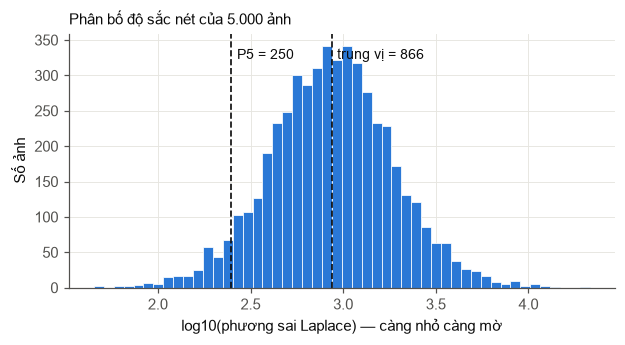

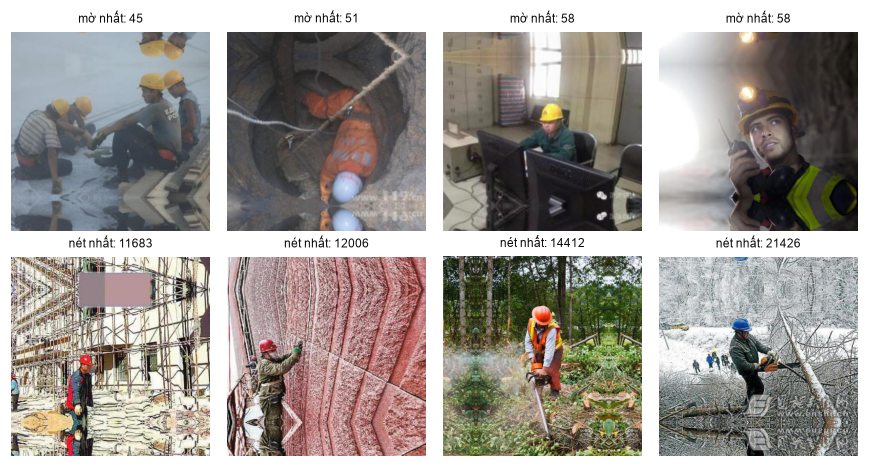

In [11]:
blur = stats.blur_laplacian_var
q = blur.quantile([0.01, 0.05, 0.10, 0.50, 0.90]).round(1)
print("Phân vị độ mờ:", q.to_dict())

fig, ax = plt.subplots(figsize=(6.4, 3.0))
ax.hist(np.log10(blur), bins=50, color=BLUE, edgecolor="white", linewidth=0.5)
for p, lab in [(0.05, "P5"), (0.50, "trung vị")]:
    v = np.log10(blur.quantile(p))
    ax.axvline(v, color=INK, linewidth=1.1, linestyle="--")
    ax.text(v + 0.03, ax.get_ylim()[1] * 0.9, f"{lab} = {10 ** v:.0f}", color=INK, fontsize=9)
ax.set_xlabel("log10(phương sai Laplace) — càng nhỏ càng mờ")
ax.set_ylabel("Số ảnh")
ax.set_title("Phân bố độ sắc nét của 5.000 ảnh", loc="left", fontsize=10)
save(fig, "fig_blur.png")

def thumbs(stems, titles, name, ncol=4, size=2.0):
    nrow = int(np.ceil(len(stems) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(ncol * size, nrow * size * 1.08))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, s, t in zip(np.ravel(axes), stems, titles):
        ax.imshow(cv2.cvtColor(cv2.imread(str(IMG_DIR / f"{s}.png")), cv2.COLOR_BGR2RGB))
        ax.set_title(t, fontsize=8)
    fig.tight_layout()
    save(fig, name)

s_sorted = stats.sort_values("blur_laplacian_var")
ex = pd.concat([s_sorted.head(4), s_sorted.tail(4)])
thumbs(ex.filename, [f"{'mờ nhất' if i < 4 else 'nét nhất'}: {v:.0f}" for i, v in enumerate(ex.blur_laplacian_var)], "fig_blur_examples.png")

**Diễn giải.** Phân bố log của phương sai Laplace gần chuẩn, không có cụm ảnh mờ tách biệt. Các ảnh "mờ nhất" chủ yếu là cảnh
ít chi tiết (sương mù, thiếu sáng, phông trơn) nhưng vẫn nhận ra người và mũ; các ảnh "nét nhất" là cảnh nhiều chi tiết
(giàn giáo, cây phủ tuyết). Như vậy chỉ số này đo cả mức chi tiết của cảnh chứ không riêng độ mờ, và không có ngưỡng
tuyệt đối dùng chung. **Kết luận:** không loại ảnh nào vì mờ; giữ chỉ số này làm biến phân nhóm khi phân tích lỗi.

## 9. Độ sáng

Độ sáng: trung vị 128.2, P10 = 84.8, P90 = 169.7, nhỏ nhất 10.1, lớn nhất 232.3
Ảnh rất tối (< 50): 91 | ảnh rất sáng (> 200): 81


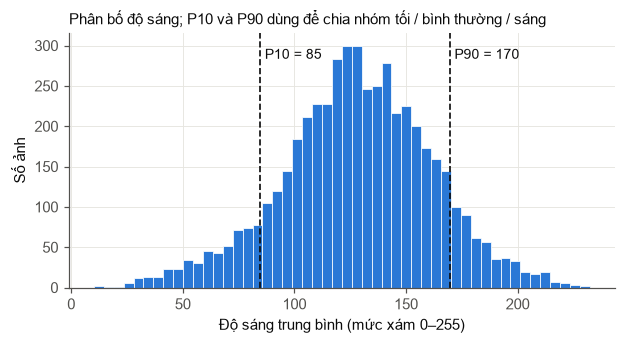

In [12]:
br = stats.brightness
p10, p90 = br.quantile([0.10, 0.90])
stats["light_group"] = pd.cut(br, [-1, p10, p90, 256], labels=["tối", "bình thường", "sáng"])
print(f"Độ sáng: trung vị {br.median():.1f}, P10 = {p10:.1f}, P90 = {p90:.1f}, nhỏ nhất {br.min():.1f}, lớn nhất {br.max():.1f}")
print("Ảnh rất tối (< 50):", (br < 50).sum(), "| ảnh rất sáng (> 200):", (br > 200).sum())

fig, ax = plt.subplots(figsize=(6.4, 3.0))
ax.hist(br, bins=50, color=BLUE, edgecolor="white", linewidth=0.5)
for v, lab in [(p10, "P10"), (p90, "P90")]:
    ax.axvline(v, color=INK, linewidth=1.1, linestyle="--")
    ax.text(v + 2, ax.get_ylim()[1] * 0.9, f"{lab} = {v:.0f}", color=INK, fontsize=9)
ax.set_xlabel("Độ sáng trung bình (mức xám 0–255)")
ax.set_ylabel("Số ảnh")
ax.set_title("Phân bố độ sáng; P10 và P90 dùng để chia nhóm tối / bình thường / sáng", loc="left", fontsize=10)
save(fig, "fig_brightness.png")

**Diễn giải.** Độ sáng trải rộng (10–232, trung vị 128): dữ liệu có cả cảnh tối như hầm, ban đêm (91 ảnh dưới 50) và cảnh
rất sáng (81 ảnh trên 200). Nhóm tối / bình thường / sáng (theo P10, P90) được lưu trong `reports/eda/image_stats.csv` để phân
tích lỗi theo điều kiện chiếu sáng (Mục tiêu 3, Tuần 8). Tăng cường dữ liệu bằng biến đổi độ sáng và không gian màu HSV
như đề cương (Tuần 4) phù hợp với độ đa dạng này.

## 10. Ảnh trùng lặp

- **Trùng hoàn toàn:** cùng mã MD5 của mảng điểm ảnh.
- **Gần trùng:** khoảng cách Hamming giữa hai dHash 64 bit nhỏ. Tính khoảng cách cho mọi cặp theo từng khối để không
  vượt RAM, xem phân bố khoảng cách tới ảnh gần nhất để chọn ngưỡng, rồi gom các cặp thành nhóm (thành phần liên thông).

In [13]:
ok = stats[stats.readable].reset_index(drop=True)
exact = ok[ok.duplicated("md5", keep=False)].sort_values("md5")
print("Trùng hoàn toàn:", exact.md5.nunique(), "nhóm,", len(exact), "ảnh")

h = np.array([int(x, 16) for x in ok.dhash], dtype=np.uint64)
nearest = np.empty(len(h), dtype=int)
pairs = {}
for start in range(0, len(h), 500):
    d = np.bitwise_count(h[start:start + 500, None] ^ h[None, :]).astype(int)
    for k in range(d.shape[0]):
        d[k, start + k] = 99
    nearest[start:start + 500] = d.min(axis=1)
    for i, j in zip(*np.nonzero(d <= 10)):
        if start + i < j:
            pairs[(start + i, j)] = d[i, j]
print("Số ảnh theo khoảng cách Hamming tới ảnh gần nhất:", pd.Series(nearest).clip(upper=12).value_counts().sort_index().to_dict())

Trùng hoàn toàn: 0 nhóm, 0 ảnh


Số ảnh theo khoảng cách Hamming tới ảnh gần nhất: {0: 101, 1: 41, 2: 26, 3: 14, 4: 11, 5: 6, 6: 5, 7: 22, 8: 28, 9: 53, 10: 102, 11: 224, 12: 4367}


Gần trùng (Hamming ≤ 6): 98 nhóm, 204 ảnh (4.1%); nhóm lớn nhất 4 ảnh


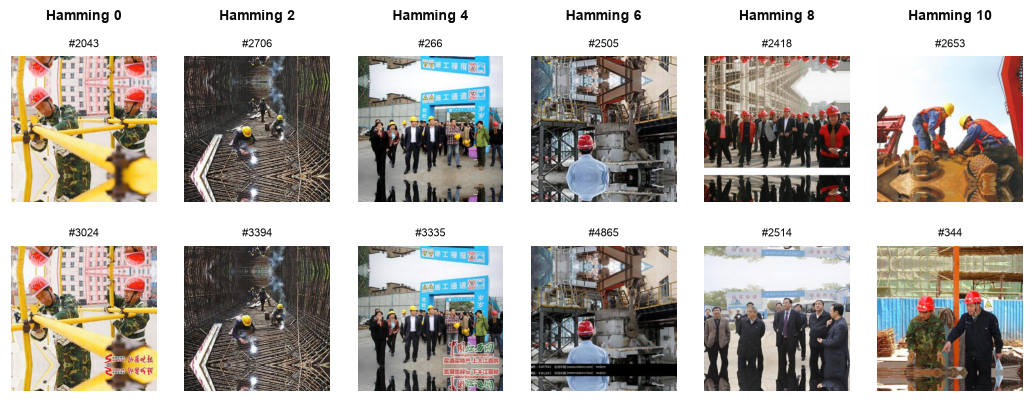

In [14]:
NEAR_DUP = 6  # ngưỡng chọn từ phân bố khoảng cách và kiểm tra trực quan bên dưới

parent = list(range(len(ok)))
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
for (i, j), d in pairs.items():
    if d <= NEAR_DUP:
        parent[find(i)] = find(j)
ok["dup_group"] = [find(i) for i in range(len(ok))]
sizes_g = ok.dup_group.value_counts()
groups = ok[ok.dup_group.isin(sizes_g[sizes_g > 1].index)][["filename", "dup_group", "dhash", "md5"]].sort_values("dup_group")
groups.to_csv(OUT / "duplicate_groups.csv", index=False)
print(f"Gần trùng (Hamming ≤ {NEAR_DUP}): {groups.dup_group.nunique()} nhóm, {len(groups)} ảnh "
      f"({len(groups) / len(ok) * 100:.1f}%); nhóm lớn nhất {sizes_g.max()} ảnh")

# Ví dụ: các cặp ở nhiều mức khoảng cách để kiểm tra ngưỡng bằng mắt
ex_pairs = []
for dist in [0, 2, 4, 6, 8, 10]:
    cand = [(i, j) for (i, j), d in pairs.items() if d == dist]
    if cand:
        ex_pairs.append((dist, *cand[len(cand) // 2]))
fig, axes = plt.subplots(2, len(ex_pairs), figsize=(1.6 * len(ex_pairs), 3.6))
for col, (dist, i, j) in zip(axes.T, ex_pairs):  # mỗi cột là một cặp ảnh
    for ax, k in zip(col, (i, j)):
        ax.imshow(cv2.cvtColor(cv2.imread(str(IMG_DIR / f"{ok.filename[k]}.png")), cv2.COLOR_BGR2RGB))
        ax.set_title(ok.filename[k].replace("hard_hat_workers", "#"), fontsize=7)
        ax.axis("off")
    col[0].text(0.5, 1.25, f"Hamming {dist}", transform=col[0].transAxes, ha="center", fontsize=9, fontweight="bold")
fig.tight_layout()
fig.subplots_adjust(hspace=0.3)
save(fig, "fig_duplicate_examples.png")

**Diễn giải.** Không có ảnh trùng hoàn toàn, nhưng có **98 nhóm (204 ảnh, 4,1%) là cùng một bức ảnh gốc**, chỉ khác logo
bản quyền, vết cắt nhẹ hoặc màu sắc. Ngưỡng Hamming 6 được chọn tại chỗ phân bố khoảng cách tới ảnh gần nhất xuống thấp
nhất (5–6 ảnh) trước khi tăng trở lại, và được kiểm tra bằng mắt: ở khoảng cách 0–6 là cùng một ảnh, ở 8–10 đã là ảnh
khác. Hệ quả: nếu chia tập ngẫu nhiên, hai bản của cùng một ảnh có thể rơi vào train và test, gây rò rỉ dữ liệu và làm
mAP bị cao ảo. Ở Tuần 4 cần chia tập theo nhóm (`duplicate_groups.csv`).

## 11. Dải đệm phản chiếu

Ảnh có dải đệm phản chiếu: 4965 / 5000 (99.3%)
Theo cặp mép: {'trên–dưới': 4433, 'trái–phải': 532}
Số ảnh theo khoảng điểm số: {'0–0.1': 4303, '0.1–0.2': 525, '0.2–0.3': 6, '0.3–0.4': 0, '0.4–0.5': 0, '0.5–0.6': 0, '0.6–0.8': 17, '0.8–1': 18, '1–inf': 0}
Độ rộng dải mỗi bên: trung vị 69 px; hai dải chiếm trung vị 33% (lớn nhất 62%) chiều tương ứng của ảnh
Tỉ lệ khung ảnh gốc suy ra (cạnh dài / cạnh ngắn), phổ biến: {1.5: 1745, 1.33: 763, 1.51: 653, 1.42: 132, 1.78: 106}


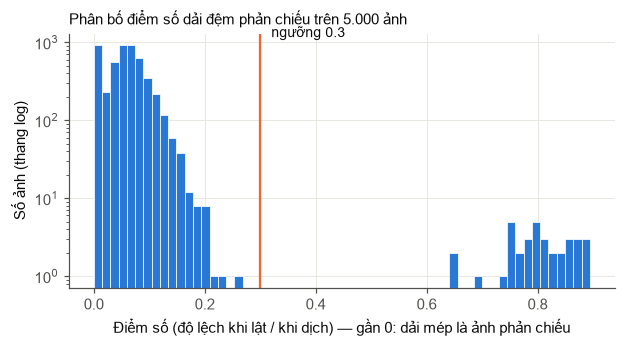

In [15]:
PAD_THRESHOLD = 0.3  # nằm giữa khoảng trống của phân bố hai đỉnh (xem biểu đồ)
stats["has_pad"] = stats.pad_score < PAD_THRESHOLD
print(f"Ảnh có dải đệm phản chiếu: {stats.has_pad.sum()} / {len(stats)} ({stats.has_pad.mean() * 100:.1f}%)")
print("Theo cặp mép:", stats[stats.has_pad].pad_axis.map({"tb": "trên–dưới", "lr": "trái–phải"}).value_counts().to_dict())
bins = pd.cut(stats.pad_score, [0, .1, .2, .3, .4, .5, .6, .8, 1, np.inf]).value_counts(sort=False)
print("Số ảnh theo khoảng điểm số:", {f"{iv.left:g}–{iv.right:g}": int(n) for iv, n in bins.items()})

pad = stats[stats.has_pad]
pad_frac = 2 * pad.pad_width / 416
print(f"Độ rộng dải mỗi bên: trung vị {pad.pad_width.median():.0f} px; hai dải chiếm trung vị {pad_frac.median() * 100:.0f}% "
      f"(lớn nhất {pad_frac.max() * 100:.0f}%) chiều tương ứng của ảnh")
aspect = 416 / (416 - 2 * pad.pad_width)
print("Tỉ lệ khung ảnh gốc suy ra (cạnh dài / cạnh ngắn), phổ biến:", aspect.round(2).value_counts().head(5).to_dict())

fig, ax = plt.subplots(figsize=(6.4, 3.0))
ax.hist(stats.pad_score.clip(upper=1.2), bins=60, color=BLUE, edgecolor="white", linewidth=0.5)
ax.set_yscale("log")
ax.axvline(PAD_THRESHOLD, color=ORANGE, linewidth=1.5)
ax.text(PAD_THRESHOLD + 0.02, ax.get_ylim()[1] * 0.9, f"ngưỡng {PAD_THRESHOLD}", color=INK, fontsize=9)
ax.set_xlabel("Điểm số (độ lệch khi lật / khi dịch) — gần 0: dải mép là ảnh phản chiếu")
ax.set_ylabel("Số ảnh (thang log)")
ax.set_title("Phân bố điểm số dải đệm phản chiếu trên 5.000 ảnh", loc="left", fontsize=10)
save(fig, "fig_padding_score.png")

**Diễn giải — phát hiện quan trọng nhất của CV-EDA.** **99,3% số ảnh (4.965/5.000) có hai dải đệm phản chiếu** ở hai mép đối
diện (89% trên–dưới, 11% trái–phải). Phân bố điểm số tách thành hai cụm rõ rệt (dưới 0,3 và trên 0,6, khoảng giữa không
có ảnh nào), nên kết quả không nhạy với việc chọn ngưỡng. Độ rộng dải cho phép suy ra tỉ lệ khung ảnh gốc là 3:2 (1,5) và
4:3 (1,33) — đúng tỉ lệ ảnh chụp thông thường — khớp với cơ chế "Fit (reflect edges)" của Roboflow. Hai dải chiếm trung
vị 33% chiều tương ứng của ảnh: khoảng một phần ba mỗi ảnh là nội dung lặp lại dạng lật gương.

### Kiểm tra bộ phát hiện bằng 300 ảnh đã đánh dấu tay ở Tuần 2

has_pad     máy: có  máy: không
mirror                         
tay: có         135           0
tay: không      161           4
Bộ phát hiện bắt được 100.0% số ảnh đã đánh dấu tay


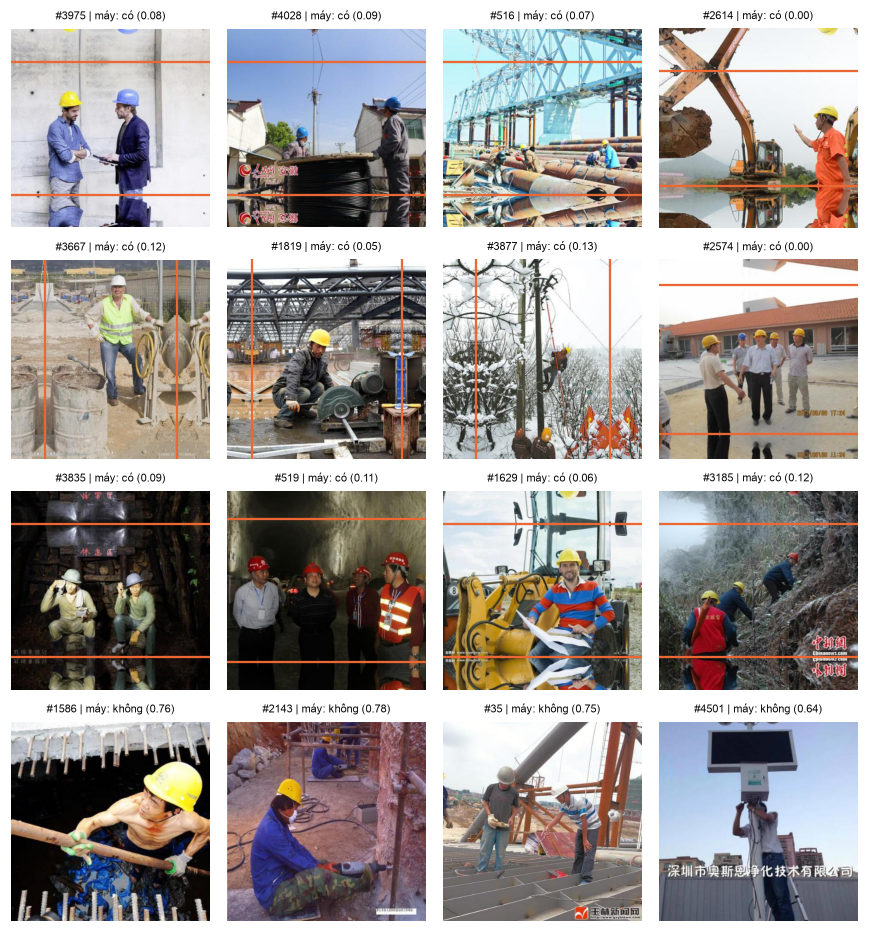

In [16]:
audit = pd.read_csv(ROOT / "reports/audit/label_audit_results.csv", encoding="utf-8-sig")
audit = audit[audit.set == "random"].merge(stats[["filename", "has_pad", "pad_score"]], on="filename")
cm = pd.crosstab(audit.mirror.map({1: "tay: có", 0: "tay: không"}), audit.has_pad.map({True: "máy: có", False: "máy: không"}))
print(cm)
recall = (audit.has_pad & (audit.mirror == 1)).sum() / (audit.mirror == 1).sum()
print(f"Bộ phát hiện bắt được {recall * 100:.1f}% số ảnh đã đánh dấu tay")

def draw_pad(stem, ax, title):
    img = cv2.cvtColor(cv2.imread(str(IMG_DIR / f"{stem}.png")), cv2.COLOR_BGR2RGB)
    r = stats.set_index("filename").loc[stem]
    ax.imshow(img)
    if r.has_pad:
        m, H = int(r.pad_width), img.shape[0]
        for v in (m, H - m):
            (ax.axhline if r.pad_axis == "tb" else ax.axvline)(v, color=ORANGE, linewidth=1.5)
    ax.set_title(title, fontsize=7)
    ax.axis("off")

# Phiếu kiểm tra cho người: ảnh máy báo có dải đệm nhưng chưa được đánh dấu tay, và các ảnh máy báo không có
check = pd.concat([audit[audit.has_pad & (audit.mirror == 0)].sample(12, random_state=42), audit[~audit.has_pad]])
fig, axes = plt.subplots(int(np.ceil(len(check) / 4)), 4, figsize=(8, 2.15 * np.ceil(len(check) / 4)))
for ax in np.ravel(axes):
    ax.axis("off")
for ax, (_, r) in zip(np.ravel(axes), check.iterrows()):
    draw_pad(r.filename, ax, f"{r.filename.replace('hard_hat_workers', '#')} | máy: {'có' if r.has_pad else 'không'} ({r.pad_score:.2f})")
fig.tight_layout()
save(fig, "fig_padding_check.png")

**Diễn giải.** Bộ phát hiện bắt đủ 135/135 ảnh được đánh dấu tay ở Tuần 2. 161 ảnh máy báo "có" nhưng chưa được đánh dấu
tay; 12 ảnh lấy ngẫu nhiên trong số này (phiếu kiểm tra ở trên) đều có dải phản chiếu thật (logo, ngày giờ, chân người
bị lật), vì khi kiểm định nhãn, ô "vùng phản chiếu" chủ yếu được đánh dấu khi dải đệm có người hoặc vật thể. Bốn ảnh máy
báo "không" là ảnh vuông, không cần đệm. **Vì vậy tỉ lệ 45% ở Tuần 2 là ước lượng thấp; tỉ lệ thực khoảng 99%.**

### Hộp nhãn nằm trong dải đệm (bản sao phản chiếu)

Hộp có tâm nằm trong dải đệm: 9134 / 75578 (12.1%)
Theo lớp (%): {'helmet': 19.1, 'head': 11.6, 'head_with_helmet': 13.5, 'person_with_helmet': 6.2, 'person_no_helmet': 5.1, 'face': 9.9}
Ảnh có ít nhất 1 hộp trong dải đệm: 2093
Trên 300 ảnh của mẫu kiểm định: 466 hộp (đếm tay ở Tuần 2: 383 hộp)


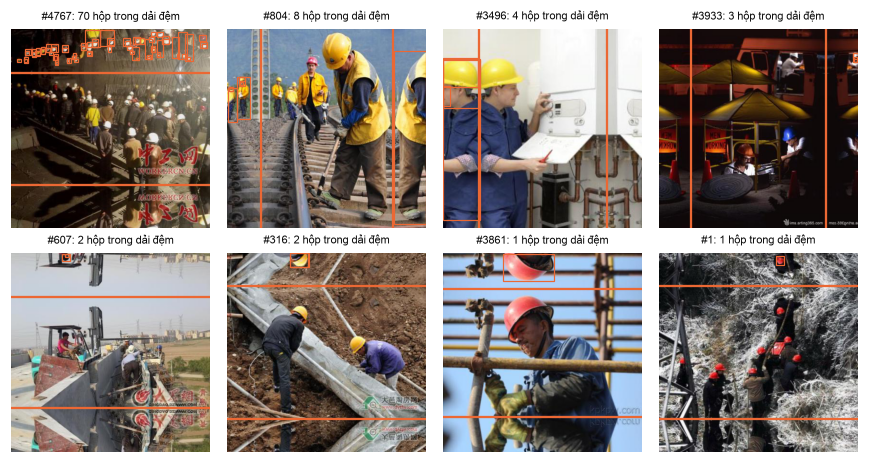

In [17]:
o = obj.merge(stats[["filename", "has_pad", "pad_axis", "pad_width"]], on="filename")
cx, cy = (o.xmin + o.xmax) / 2, (o.ymin + o.ymax) / 2
pos = np.where(o.pad_axis == "tb", cy, cx)
size_ax = np.where(o.pad_axis == "tb", o.height, o.width)
o["in_pad"] = o.has_pad & ((pos < o.pad_width) | (pos > size_ax - o.pad_width))
print(f"Hộp có tâm nằm trong dải đệm: {o.in_pad.sum()} / {len(o)} ({o.in_pad.mean() * 100:.1f}%)")
print("Theo lớp (%):", (o.groupby("class").in_pad.mean() * 100).reindex(CLASSES).round(1).to_dict())
print("Ảnh có ít nhất 1 hộp trong dải đệm:", o.groupby("filename").in_pad.any().sum())
s300 = o[o.filename.isin(audit.filename)]
print(f"Trên 300 ảnh của mẫu kiểm định: {s300.in_pad.sum()} hộp (đếm tay ở Tuần 2: 383 hộp)")

ranked = o[o.in_pad].groupby("filename").size().sort_values(ascending=False).index
ex = [ranked[k] for k in np.linspace(0, len(ranked) - 1, 8).astype(int)]  # trải đều từ nhiều đến ít hộp trong dải đệm
fig, axes = plt.subplots(2, 4, figsize=(8, 4.3))
for ax, s in zip(np.ravel(axes), ex):
    draw_pad(s, ax, f"{s.replace('hard_hat_workers', '#')}: {int(o[(o.filename == s)].in_pad.sum())} hộp trong dải đệm")
    for _, b in o[(o.filename == s) & o.in_pad].iterrows():
        ax.add_patch(plt.Rectangle((b.xmin, b.ymin), b.bw, b.bh, fill=False, edgecolor=ORANGE, linewidth=0.8))
fig.tight_layout()
save(fig, "fig_padding_examples.png")

**Diễn giải.** **12,1% số hộp (9.134) nằm trong dải đệm**, tức là bản sao phản chiếu, thường lộn ngược, của đối tượng thật
(Roboflow phản chiếu cả nhãn). `helmet` có tỉ lệ cao nhất (19,1%), lớp vi phạm `person_no_helmet` 5,1%. Trên 300 ảnh mẫu,
máy đếm 466 hộp so với 383 hộp đếm tay ở Tuần 2, phù hợp với việc đếm tay bỏ sót. Hệ quả: (1) mô hình học cả người lộn
ngược, vốn không xuất hiện ở camera công trường; (2) chỉ số trên tập test nội bộ tính cả các bản sao này nên có thể không
phản ánh đúng khả năng trên camera thật, góp phần vào chênh lệch ngoài miền (Mục tiêu 4). Đề xuất cho Tuần 4: so sánh
bằng thực nghiệm hai phương án "giữ nguyên" và "cắt bỏ dải đệm, loại các hộp nằm trong dải đệm".

## 12. Tổng kết

| Phát hiện | Ý nghĩa với bài toán | Hướng xử lý |
|---|---|---|
| Mất cân bằng lớp: `person_no_helmet` 6,9%, ít hơn lớp nhiều nhất 3,67 lần | Nguy cơ Recall lớp vi phạm thấp | M2 (Tuần 7); chia tập có phân tầng (Tuần 4) |
| Vật thể nhỏ: 55,5% hộp < 32×32 px; `face`, `head`, `helmet` chủ yếu nhỏ; 7,3% hộp có cạnh < 8 px | Khó phát hiện mũ, đầu ở xa | Đánh giá STAL (M1); phân tích lỗi theo kích thước (Tuần 8); cân nhắc lọc hộp < 4 px (Tuần 4) |
| **Dải đệm phản chiếu: 99,3% ảnh, chiếm ~33% chiều ảnh; 12,1% hộp là bản sao phản chiếu** | Học và đánh giá trên đối tượng lộn ngược; tăng chênh lệch ngoài miền | Thực nghiệm cắt dải đệm, loại hộp trong dải (Tuần 4) |
| Gần trùng: 98 nhóm, 204 ảnh (4,1%) | Rò rỉ dữ liệu nếu chia tập ngẫu nhiên | Chia tập theo nhóm (Tuần 4) |
| Độ mờ, độ sáng: không có ảnh hỏng; độ sáng đa dạng (10–232) | Dữ liệu đủ đa dạng điều kiện chụp | Giữ toàn bộ ảnh; dùng làm biến phân nhóm lỗi (Tuần 8); tăng cường độ sáng/HSV (Tuần 4) |
| Ảnh lỗi: 0; tọa độ bất hợp lý: 0 | — | Không cần xử lý |

**Điều chỉnh so với kết quả Tuần 2:** tỉ lệ ảnh có vùng phản chiếu là khoảng 99%, không phải 45% như ước lượng từ đánh dấu
tay (lúc kiểm định chủ yếu chỉ đánh dấu khi dải đệm có đối tượng).

In [18]:
# Lưu thêm cột nhóm độ sáng và cờ dải đệm để dùng ở Tuần 4 (chia tập, tiền xử lý) và Tuần 8 (phân tích lỗi)
stats.to_csv(STATS, index=False)
print("Đã lưu", STATS.relative_to(ROOT), "với các cột:", list(stats.columns))

Đã lưu reports/eda/image_stats.csv với các cột: ['filename', 'readable', 'height', 'width', 'blur_laplacian_var', 'brightness', 'md5', 'dhash', 'pad_axis', 'pad_width', 'pad_score', 'light_group', 'has_pad']
